    
---

# Project 1: Snowball Earth




In [1]:
# Load libraries
import numpy as np
import math
import matplotlib.pyplot as plt

# Change degrees to radians
pi=np.pi
deg2rad=pi/180
rad2deg=1/deg2rad

In [2]:
# Define the latitude dependent insolation
def Q_lat(xs,L=1,S0=1354.0):    

    return  L*(S0/4)*(1 - 0.241*( 3*np.square(xs) - 1 ))
 

In [3]:
# Define the albedo function
def albedo(T,jmx):
    alb=np.ones(jmx)*0.3
    k=np.argwhere(T<=-2)
    alb[k]=0.6# recalculate albedo for snowline at T=-10C
    return alb

In [4]:
# Define the heat diffusion function

def D_lat(xs,D0=0.44):
    return D0*np.ones(len(xs))

## CO2 outgassing

In [5]:
CO2_initial = 300
def outgassing(yr):
    outgassing_yr = 0.0129
    CO2 = CO2_initial + yr * outgassing_yr
    return CO2
# test

# CO2 = outgassing(100000)


In [6]:
# Define the CO2 forcing function ( new A & B)

def greenhouse(CO2):
    ratioc = np.log(CO2 / 300)
    A_kelvin = -326.4 + 9.161*ratioc - 3.164*ratioc**2 + 0.5468*ratioc**3
    B = 1.953 - 0.04866*ratioc + 0.01309*ratioc**2 - 0.002577*ratioc**3
    A = A_kelvin + 273.15*B
    return A, B

#test
# greenhouse(720)

In [7]:
# Calculate ice thickness ( latitude dependent)


def ice_thickness(T):
    z = 2.5*(-2-T)/0.06 
    z = np.maximum(0, z)
    return z
# test
ice_thickness(-27)

np.float64(1041.6666666666667)

In [8]:
# Define functions used for matrix operations when solving the equations

# Define the intermediate function to calculate matrix coefficients
def setupfastMh(delx,jmx,D,B,Cl,delt):
    #set up lambda array.
    lam=(1-np.arange(-1,1,delx)*np.arange(-1,1,delx))/(delx*delx)
    lam=D[0:jmx]*lam
    M=np.zeros((jmx,jmx))
    M[0,0]=-B-lam[1]
    M[0,1]=lam[1]
    M[jmx-1,jmx-2]=lam[jmx-1]
    M[jmx-1,jmx-1]=-B-lam[jmx-1]
    for jj in range(jmx-2):
        j=jj+2
        M[j-1,j-2] = lam[j-1]
        M[j-1,j-1]   = -B - (lam[j]+lam[j-1])
        M[j-1,j] = lam[j]
    # add in heat capacities
    M=M/Cl
    # calculate the inverse of M', the matrix operator.
    Mh=M
    return Mh

def setupfastinvM(Mh,jmx,delt):
    M=0.5*Mh
    for j in range(jmx):
        M[j,j]=M[j,j]-1/delt
    invM = np.linalg.inv(M) 
    return invM

## North model

In [9]:
# This is the main script in the steady state version of the North model

# First, set all parameters: physical parameters, model parameters, model flag options
# Set physical parameters
# L=1 #the relative strength of the solar constant, 1=present
# A=203.3
# Toffset=0 
# 
CO2_initial = 300
CO2 = outgassing(0)
# B=2.09 # temperature dependence of outgoing longwave radiation

def snowball(L, CO2, Toffset):
    S0=1354.0 #The solar constant, corresponds to Q_0=338.5 W/m2
    Dmag=0.44
    Cl=9.8 #unit W/m2*yr/K
    # Set model parameters
    jmx=251 # number of grid points
    delt=1/50 # time step in years (ca. 1 week)
    NMAX=10000
    delx=2/jmx


    # define an array with latitude steps in both x and phi
    x= np.linspace(-1,1,jmx)
    phi=np.arcsin(x)*rad2deg
    # Second, calculate all the unknowns, i.e. T, Tglob, F, divF, alb, S
    # Calculate an array of annual mean insolation for the latitudes steps
    S=Q_lat(x,L,S0)

    # Calculate A from CO2
    A, B = greenhouse(CO2)
  
    # Calculate an array of diffussion constants
    D=D_lat(x,Dmag)
    # define initial T array
    T = 20*(1-2*np.square(x))

    T=T+Toffset
    Tinit = T.copy()

    # Calculate global mean temperature
    Tglob=np.mean(T) #ok to take the mean when we use x

    # Calculate initial albedo
    alb=albedo(T,jmx)

    # Initial boundary conditions
    src=(1-alb)*S/Cl-A/Cl # need to include CO2 change here
    Mh=setupfastMh(delx,jmx,D,B,Cl,delt)
    invM=setupfastinvM(Mh,jmx,delt)
    h=np.dot(Mh,T)+src


    # Start time-stepping loop
    for n in range(NMAX):
        Tglob_prev=Tglob
        # calculate src for this loop
        alb=albedo(T,jmx)
        src=(1-alb)*S/Cl-A/Cl
        # Calculate new T.
        T=-np.dot(invM,0.5*(h+src)+T/delt)
    
        # Calculate h for next loop.
        h=np.dot(Mh,T)+src
        # Check to see if global mean temperature has converged
        Tglob=np.mean(T)
        Tchange = Tglob-Tglob_prev
        if abs(Tchange)< 1e-12:
            break

    # sea ice thickness

    ice = ice_thickness(T)
    ice_mean = np.mean(ice_thickness(T))
    a=6.37e+6; # earth radius in meters
    Mh_flux=setupfastMh(delx,jmx,D,0,1,delt)
    Dmp=D[0:jmx]
    divF=np.dot(Mh_flux,T)
    F=-2*math.pi*a*a*np.sqrt(1-x*x)*Dmp*np.gradient(T,delx)
    return {
    'x': x, #
    'phi': phi, #
    'T': T, #
    'alb': alb, #
    'CO2':CO2, #
    'Tglob': Tglob, #
    'F': F, # 
    'divF': divF, #
    'S': S, # 
    'A': A, # 
    'B':B, # 
    'ice':ice, #
    'ice mean': ice_mean #
}

variables = snowball(1, CO2, -40)

print(variables['CO2'])
print(variables['A'])
print(variables['Tglob'])
# print(np.max(variables['T']))
print(variables['ice'])
print(variables['ice mean'])

300.0
207.06195000000002
-36.82693353790025
[2040.80352837 2026.65117723 2012.61249959 1998.68749545 1984.87616482
 1971.17850769 1957.59452406 1944.12421394 1930.76757732 1917.5246142
 1904.39532458 1891.37970847 1878.47776586 1865.68949676 1853.01490116
 1840.45397906 1828.00673046 1815.67315537 1803.45325378 1791.34702569
 1779.35447111 1767.47559003 1755.71038245 1744.05884838 1732.52098781
 1721.09680074 1709.78628718 1698.58944712 1687.50628056 1676.53678751
 1665.68096795 1654.93882191 1644.31034936 1633.79555032 1623.39442478
 1613.10697274 1602.93319421 1592.87308918 1582.92665766 1573.09389963
 1563.37481511 1553.7694041  1544.27766658 1534.89960257 1525.63521207
 1516.48449506 1507.44745156 1498.52408156 1489.71438507 1481.01836208
 1472.43601259 1463.9673366  1455.61233412 1447.37100514 1439.24334967
 1431.22936769 1423.32905922 1415.54242426 1407.86946279 1400.31017483
 1392.86456038 1385.53261942 1378.31435197 1371.20975803 1364.21883758
 1357.34159064 1350.5780172  1343.

In [10]:
CO2_dev = [] # List CO2 
year_dev = [] # List Year
Tglob_dev = [] # list mean global temperature
I0_lat_dev = [] 
I15_lat_dev = []
I30_lat_dev = []
I45_lat_dev = []
I60_lat_dev = []
I75_lat_dev = []
I90_lat_dev = []
T_grid_dev = []      
ice_grid_dev = []    


 # 12620000 - 12700000 
for yr in range(0, 25000000, 10000):
    CO2 = outgassing(yr)
    variables = snowball(1, CO2, -40)
    
    CO2_dev.append(CO2)
    year_dev.append(yr)
    Tglob_dev.append(variables['Tglob'])
    T_grid_dev.append(variables['T'].copy())
    ice_grid_dev.append(variables['ice'].copy())

    I0_lat_dev.append(
        variables['ice'][np.argmin(np.abs(variables['phi'] - 0))])

    I15_lat_dev.append(
        variables['ice'][np.argmin(np.abs(variables['phi'] - 15))])

    I30_lat_dev.append(
        variables['ice'][np.argmin(np.abs(variables['phi'] - 30))])

    I45_lat_dev.append(
        variables['ice'][np.argmin(np.abs(variables['phi'] - 45))])

    I60_lat_dev.append(
        variables['ice'][np.argmin(np.abs(variables['phi'] - 60))])

    I75_lat_dev.append(
        variables['ice'][np.argmin(np.abs(variables['phi'] - 75))])

    I90_lat_dev.append(
        variables['ice'][np.argmin(np.abs(variables['phi'] - 90))])

    
    if np.max(variables['T']) > -1:
        break
# investigate between 12600000 to 12700000
print('Year:', yr)
print('CO2:', CO2)
print('Tmax:', np.max(variables['T']))
print('Tglob:', variables['Tglob'])
print('year list', year_dev)
print('CO2 list', CO2_dev)
print('Global mean list', CO2_dev)

Year: 19920000
CO2: 257268.0
Tmax: 75.07071659903782
Tglob: 60.91905021162436
year list [0, 10000, 20000, 30000, 40000, 50000, 60000, 70000, 80000, 90000, 100000, 110000, 120000, 130000, 140000, 150000, 160000, 170000, 180000, 190000, 200000, 210000, 220000, 230000, 240000, 250000, 260000, 270000, 280000, 290000, 300000, 310000, 320000, 330000, 340000, 350000, 360000, 370000, 380000, 390000, 400000, 410000, 420000, 430000, 440000, 450000, 460000, 470000, 480000, 490000, 500000, 510000, 520000, 530000, 540000, 550000, 560000, 570000, 580000, 590000, 600000, 610000, 620000, 630000, 640000, 650000, 660000, 670000, 680000, 690000, 700000, 710000, 720000, 730000, 740000, 750000, 760000, 770000, 780000, 790000, 800000, 810000, 820000, 830000, 840000, 850000, 860000, 870000, 880000, 890000, 900000, 910000, 920000, 930000, 940000, 950000, 960000, 970000, 980000, 990000, 1000000, 1010000, 1020000, 1030000, 1040000, 1050000, 1060000, 1070000, 1080000, 1090000, 1100000, 1110000, 1120000, 1130000,

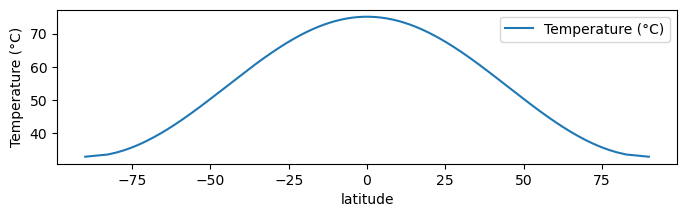

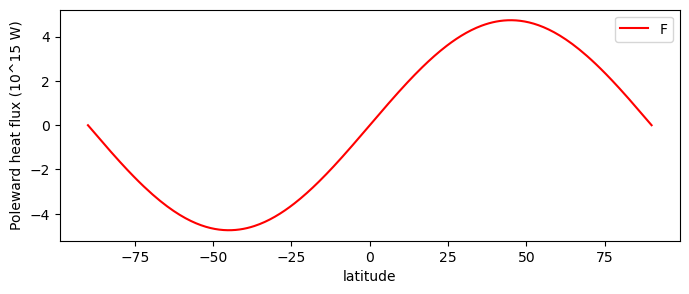

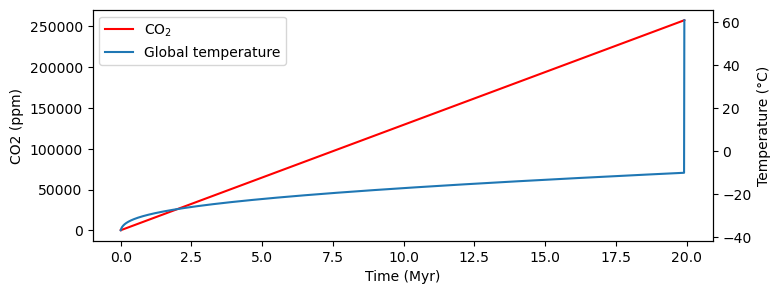

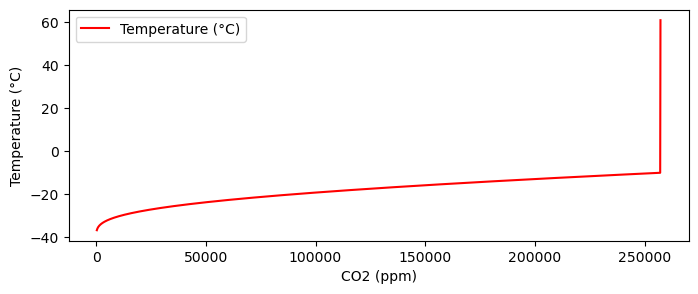

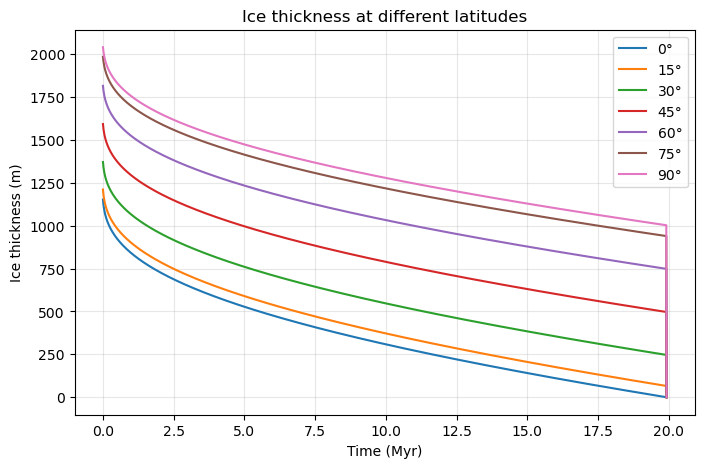

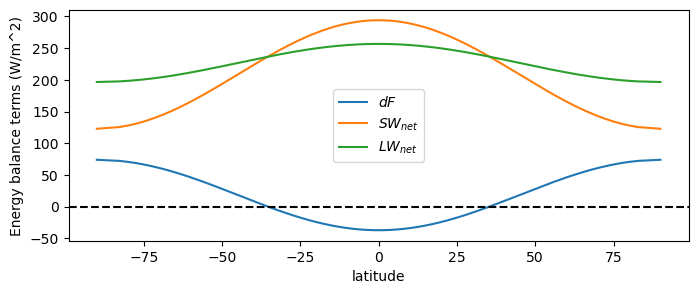

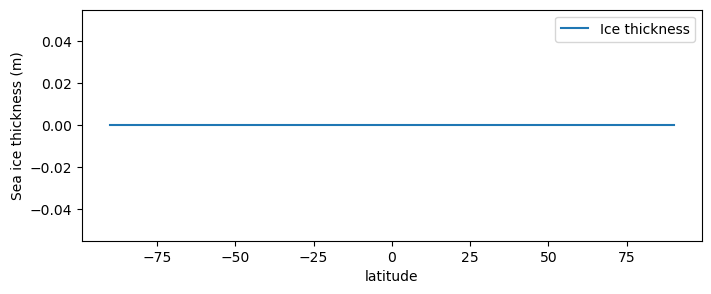

In [11]:
# Plotting in the steady state North model: bab
# plot the temperature and energy fluxes in equilibrium 

fig = plt.subplots(figsize=(8,2))
plt.plot(variables['phi'], variables['T'], label='Temperature (°C)')
plt.xlabel('latitude')
plt.ylabel('Temperature (°C)')
plt.legend()
plt.savefig('plot1.png', dpi=300, bbox_inches='tight')
plt.show()

fig = plt.subplots(figsize=(8,3))
plt.plot(variables['phi'], variables['F']*1e-15, 'r', label='F')
plt.xlabel('latitude')
plt.ylabel('Poleward heat flux (10^15 W)')
plt.legend()
plt.savefig('plot2.png', dpi=300, bbox_inches='tight')
plt.show()


# Double axe plot
fig, ax1 = plt.subplots(figsize=(8,3))
# Left y-axis: CO2
l1, = ax1.plot(np.array(year_dev)/1e6, CO2_dev, 'r', label='CO$_2$')
ax1.set_xlabel('Time (Myr)')
ax1.set_ylabel('CO2 (ppm)')
# Right y-axis: Temperature
ax2 = ax1.twinx()
l2, = ax2.plot(np.array(year_dev)/1e6, Tglob_dev, label='Global temperature')
ax2.set_ylabel('Temperature (°C)')
# Combined legend from both axes
ax1.legend(handles=[l1, l2], labels=['CO$_2$', 'Global temperature'], loc='upper left')
plt.savefig('plot3.png', dpi=300, bbox_inches='tight')
plt.show()

fig = plt.subplots(figsize=(8,3))
plt.plot(CO2_dev, Tglob_dev, 'r', label='Temperature (°C)')
plt.xlabel('CO2 (ppm)')
plt.ylabel('Temperature (°C)')
plt.legend()
plt.savefig('plot4.png', dpi=300, bbox_inches='tight')
plt.show()

fig = plt.subplots(figsize=(8,5))
plt.plot(np.array(year_dev)/1e6, I0_lat_dev, label='0°')
plt.plot(np.array(year_dev)/1e6, I15_lat_dev, label='15°')
plt.plot(np.array(year_dev)/1e6, I30_lat_dev, label='30°')
plt.plot(np.array(year_dev)/1e6, I45_lat_dev, label='45°')
plt.plot(np.array(year_dev)/1e6, I60_lat_dev, label='60°')
plt.plot(np.array(year_dev)/1e6, I75_lat_dev, label='75°')
plt.plot(np.array(year_dev)/1e6, I90_lat_dev, label='90°')

plt.xlabel('Time (Myr)')
plt.ylabel('Ice thickness (m)')
plt.title('Ice thickness at different latitudes')
plt.legend()
plt.grid(alpha=0.3)
plt.savefig('plot5.png', dpi=300, bbox_inches='tight')
plt.show()


fig = plt.subplots(figsize=(8,3))
plt.plot(variables['phi'], variables['divF'], label='$dF$')
plt.plot(variables['phi'], (1-variables['alb'])*variables['S'], label='$SW_{net}$')
plt.plot(variables['phi'], variables['A'] + variables['B']*variables['T'], label='$LW_{net}$')
plt.axhline(y=0, linestyle='--', color='k')
plt.xlabel('latitude')
plt.ylabel('Energy balance terms (W/m^2)')
plt.legend()
plt.savefig('plot6.png', dpi=300, bbox_inches='tight')
plt.show()

fig = plt.subplots(figsize=(8,3))
plt.plot(variables['phi'], variables['ice'], label='Ice thickness')
plt.xlabel('latitude')
plt.ylabel('Sea ice thickness (m)')
plt.legend()
plt.savefig('plot7.png', dpi=300, bbox_inches='tight')
plt.show()

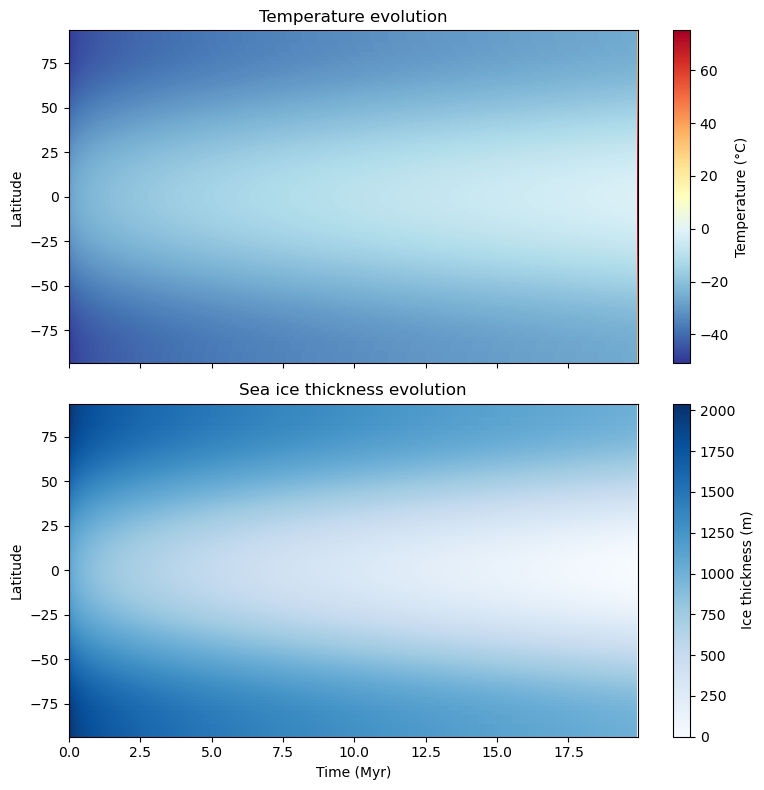

In [12]:
# Define Grid for heatmap
T_grid = np.array(T_grid_dev)
ice_grid = np.array(ice_grid_dev)



# Heatmaps of temperature and ice thickness
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 8), sharex=True)

# Heatmap 1: Temperature 
pc1 = ax1.pcolormesh(np.array(year_dev)/1e6, variables['phi'], T_grid.T, cmap='RdYlBu_r', shading='auto')
fig.colorbar(pc1, ax=ax1, label='Temperature (°C)')
ax1.set_ylabel('Latitude')
ax1.set_title('Temperature evolution')

# Heatmap 2: Sea ice thickness
pc2 = ax2.pcolormesh(np.array(year_dev)/1e6, variables['phi'], ice_grid.T, cmap='Blues', shading='auto')
fig.colorbar(pc2, ax=ax2, label='Ice thickness (m)')
ax2.set_ylabel('Latitude')
ax2.set_xlabel('Time (Myr)')
ax2.set_title('Sea ice thickness evolution')

plt.tight_layout()
plt.savefig('plot8.png', dpi=300, bbox_inches='tight')
plt.show()